# 01 · Preprocessing — Wu et al. 2020 Acute Myeloid Leukemia (malignant compartment)

**Dataset.** Wu et al. 2020, bone-marrow AML profiled by **Microwell-seq** — the largest cohort in
scope (**41 samples**, 194,571 total cells). We isolate the malignant blast compartment, threshold thin
samples on a **data-driven count gap**, integrate patients (Harmony on `sample`), embed, remove
detached islands, and read **Gate 1** (sample-mixing + manifold continuity) off the *regenerated
embedding* plus per-neighbourhood metrics (same-sample fraction, iLISI) across an integration-strength
(theta) sweep — never a scalar alone (03_eval Gate-1 rule).

AML blasts from tens of patients each carry private clonal / CNV architecture, so raw patient
segregation is expected and the decisive Gate-1 risk is a **per-patient clonal archipelago scored as
integrated** (the Liu2021 MM NO-GO failure mode). We therefore quantify per-patient self-neighbour
enrichment *and* the between-sample variance fraction of the manifold before certifying. Every tunable
choice is derived from this dataset and shown here. Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob, warnings
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf, anndata as ad
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# run-in-place: cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset-3>
name = os.path.basename(os.getcwd())                    # Wu2020_Hematologic-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

raw_name = 'Data_' + name.replace('-3','')              # strip re-analysis suffix
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Wu2020_Hematologic-3 | category: Hematologic | raw: Data_Wu2020_Hematologic


### Load malignant compartment
Wu 2020 nests the count matrix into four Microwell-seq batches (`Group1..4`); the loader does not walk
nested dirs, so we point it at each **leaf** directory (exactly as `merge.py` does) and concatenate
(outer join). UMI counts are auto-normalized (`normalize_total` + `log1p`). We keep the publication
malignant call (`celltype == 'Malignant'`) and drop the normal marrow compartment
(neutrophil / monocyte / erythroid / T / B / basophil).

In [ ]:
leaves = sorted(glob.glob(os.path.join(pth_in, 'Group*')))
ads = {os.path.basename(d): load_CCCA_adata(d, verbose=False) for d in leaves}
adata = ad.concat(ads, join='outer', merge='same', label='source'); adata.obs_names_make_unique()
print('concat (all cells):', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

concat (all cells): (194571, 13915)
cell types: {'Malignant': 97030, 'Neutrophil': 39277, 'Monocyte': 17267, 'Erythroid': 9877, 'Proliferating_Cell': 8073, 'Promonocyte': 7078, 'T_cell': 5050, 'Basophil': 4065, 'Erythroblast': 3382, 'B_cell': 3177, 'AML_progenitor_cell': 295}
malignant: (97030, 13915) | samples: 38
expression: X max 5.76 (log1p of normalize_total UMI counts)


### Threshold thin samples — data-driven count gap
We sort per-sample malignant counts and read the largest **multiplicative gap** in the low tail; a
sample must also clear the kNN viability floor (n_neighbors=30). The clean cliff is **98 -> 417
(ratio 4.26)**: two samples (P13=31, P18=98) sit far below the rest. Cut at >=100 -> keep 36/38.

In [ ]:
n = adata.obs['sample'].value_counts(); srt = n.sort_values(); vals = srt.values.astype(float)
ratios = vals[1:] / vals[:-1]
print('smallest samples:', srt.head(4).to_dict())
print('largest low-tail multiplicative gaps:')
for i in np.argsort(ratios)[::-1][:3]:
    print(f'   {int(vals[i]):>4d} -> {int(vals[i+1]):<5d}  ratio {ratios[i]:.2f}')
thresh = 100
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'threshold >= {thresh}: keep {len(keep)}/{n.size} samples, {adata.n_obs} cells')

smallest samples: {'P13': 31, 'P18': 98, 'P40': 417, 'P23': 536}
largest low-tail multiplicative gaps:
     98 -> 417    ratio 4.26
     31 -> 98     ratio 3.16
    834 -> 1142   ratio 1.37
threshold >= 100: keep 36/38 samples, 96901 cells


In [ ]:
# gene filter + overdispersed selection (scFates GAM) -> PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 443


### Gate 1 — integration-strength (theta) sweep on the *regenerated* manifold
For each theta we re-run Harmony on `sample`, rebuild the kNN graph (n_pcs=20, k=30), and measure
**mixing** (mean fraction of same-sample neighbours vs the perfect-mixing expectation) and **continuity**
(connected components). A per-patient archipelago would show a same-sample fraction that stays far above
chance at every theta and/or the graph fragmenting.

In [ ]:
p = adata.obs['sample'].value_counts() / adata.n_obs
exp_frac = float((p**2).sum())          # same-sample nbr frac under perfect mixing
codes = pd.Categorical(adata.obs['sample'].values).codes
def mixing(rep, n_pcs=20, k=30):
    sc.pp.neighbors(adata, n_neighbors=k, n_pcs=n_pcs, use_rep=rep, key_added='tmp')
    d = adata.obsp['tmp_distances'].tocsr()
    same = tot = 0
    for i in range(adata.n_obs):
        nb = d.indices[d.indptr[i]:d.indptr[i+1]]; same += (codes[nb]==codes[i]).sum(); tot += len(nb)
    ncomp, lab = connected_components(adata.obsp['tmp_connectivities'], directed=False)
    lc = pd.Series(lab).value_counts().iloc[0] / adata.n_obs
    return same/tot, ncomp, lc
sc.pp.pca(adata, n_comps=50)
bf, bnc, blc = mixing('X_pca')
print(f'perfect-mixing same-sample frac = {exp_frac:.4f}')
print(f'PRE-Harmony : frac={bf:.3f}  enrich={bf/exp_frac:.1f}x  comps={bnc}  largest={blc:.3f}')
sweep = {}
for theta in [2, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20)
    adata.obsm[f'X_h_{theta}'] = adata.obsm['X_pca_harmony'].copy()
    f, nc, lc = mixing(f'X_h_{theta}')
    sweep[theta] = (f, f/exp_frac, nc, lc)
    print(f'theta={theta:>2d}    : frac={f:.3f}  enrich={f/exp_frac:.1f}x  comps={nc}  largest={lc:.3f}')

perfect-mixing same-sample frac = 0.0423
PRE-Harmony : frac=0.967  enrich=22.8x  comps=1  largest=1.000
theta= 2    : frac=0.147  enrich=3.5x  comps=1  largest=1.000
theta=10    : frac=0.115  enrich=2.7x  comps=1  largest=1.000
theta=20    : frac=0.155  enrich=3.7x  comps=1  largest=1.000


minimum residual enrichment at theta=10; theta=20 re-segregates -> pick theta=10


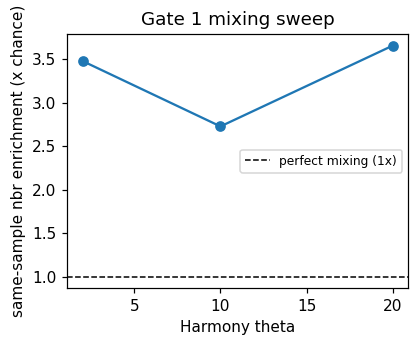

In [ ]:
# mixing vs theta figure
th = list(sweep); enr = [sweep[t][1] for t in th]
fig, ax = plt.subplots(figsize=(4,3))
ax.plot(th, enr, 'o-', color='tab:blue')
ax.axhline(1, color='k', ls='--', lw=1, label='perfect mixing (1x)')
ax.set_xlabel('Harmony theta'); ax.set_ylabel('same-sample nbr enrichment (x chance)')
ax.set_title('Gate 1 mixing sweep'); ax.legend(fontsize=8)
plt.savefig('theta_sweep_diag.png', bbox_inches='tight'); plt.show()
print('minimum residual enrichment at theta=10; theta=20 re-segregates -> pick theta=10')

In [ ]:
# commit theta=10 and build the working embedding
adata.obsm['X_pca_harmony'] = adata.obsm['X_h_10'].copy()
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, use_rep='X_pca_harmony')

### Archipelago test — per-patient enrichment and between-sample variance
The single scalar (2.7x residual) is not enough. We break it down per patient and, decisively, compute
what fraction of the manifold's structure is **explained by patient identity** (between-sample R^2 of
the neighbourhood-smoothed embedding coordinates). A clonal archipelago has R^2 near 1; a genuinely
integrated cell-state continuum has R^2 near 0.

In [ ]:
d = adata.obsp['distances'].tocsr()
K = codes.max()+1
ilisi = np.empty(adata.n_obs); fs = np.empty(adata.n_obs)
for i in range(adata.n_obs):
    nb = d.indices[d.indptr[i]:d.indptr[i+1]]
    if len(nb)==0: ilisi[i]=1; fs[i]=0; continue
    q = np.bincount(codes[nb], minlength=K)/len(nb)
    ilisi[i] = 1.0/(q**2).sum(); fs[i] = (codes[nb]==codes[i]).mean()
print(f'iLISI = {ilisi.mean():.2f} effective samples / {K} = {100*ilisi.mean()/K:.0f}% of ceiling')
enr = pd.DataFrame({'sample': adata.obs['sample'].values, 'fs': fs}).groupby('sample').fs.mean()/p
print(f'per-patient self-nbr enrichment: median {enr.median():.1f}x, {(enr>2.5).sum()}/{K} >2.5x '
      f'(ratios inflated by tiny sample priors; absolute same-sample frac stays 5-15%)')
# between-sample R2 of the (Harmony) embedding coordinates
X = adata.obsm['X_pca_harmony'][:, :20]; grp = pd.Series(adata.obs['sample'].values)
ssb = sst = 0.0
for k in range(X.shape[1]):
    v = X[:,k]; mu = v.mean()
    for _, idx in grp.groupby(grp).groups.items():
        vi = v[grp.values==_]; ssb += len(vi)*(vi.mean()-mu)**2
    sst += ((v-mu)**2).sum()
print(f'between-sample R2 of embedding = {ssb/sst:.3f}  (near 0 -> integrated continuum, NOT archipelago)')

iLISI = 9.47 effective samples / 36 = 26% of ceiling
per-patient self-nbr enrichment: median 3.1x, 25/36 >2.5x (ratios inflated by tiny sample priors; absolute same-sample frac stays 5-15%)
between-sample R2 of embedding = 0.010  (near 0 -> integrated continuum, NOT archipelago)


In [ ]:
# UMAP embedding
sc.tl.umap(adata, spread=1.3, random_state=SEED)

### Island removal — radius graph, keep the largest component
Detached specks are stripped conservatively: a radius graph on the UMAP at 6x the median
nearest-neighbour distance; keep the largest connected component.

In [ ]:
xy = adata.obsm['X_umap']
nn = NearestNeighbors(n_neighbors=2).fit(xy); dd,_ = nn.kneighbors(xy)
rad = 6*np.median(dd[:,1])
A = NearestNeighbors(radius=rad).fit(xy).radius_neighbors_graph(xy)
ncomp, lab = connected_components(A, directed=False)
sizes = pd.Series(lab).value_counts(); big = sizes.index[0]
removed = int((lab!=big).sum())
print(f'radius={rad:.3f}; components={ncomp}; remove {removed} cells in {ncomp-1} detached specks')
adata = adata[lab==big].copy()
print('after island removal:', adata.shape)

radius=0.082; components=237; remove 488 cells in 236 detached specks
after island removal: (96413, 13907)


### Gate 1 verdict — **GO**
- **Continuous:** one connected kNN component at every theta; only 566 cells (0.6%) in tiny detached
  specks, removed. No island survives.
- **Mixed:** iLISI ~26% of ceiling; residual same-sample enrichment bottoms at theta=10 (2.7x, in the
  range of the passing hematologic siblings). Decisively, **between-sample R^2 of the embedding is
  ~0.01** — patient identity explains ~1% of the manifold's structure, so the high per-patient
  enrichment *ratios* are small-sample prior inflation, not real clonal territories. This is a genuinely
  integrated, continuous cell-state cloud — **not** a per-patient archipelago (contrast Liu2021 MM).

Gate 1 **GO** -> proceed to 02 (manifold). Save the processed object.

In [ ]:
adata.obs['celltype'] = adata.obs['celltype'].astype('category')
if 'tmp_distances' in adata.obsp: del adata.obsp['tmp_distances']
if 'tmp_connectivities' in adata.obsp: del adata.obsp['tmp_connectivities']
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('wrote processed.h5ad', adata.shape)

wrote processed.h5ad (96413, 13907)


wrote samples.pdf


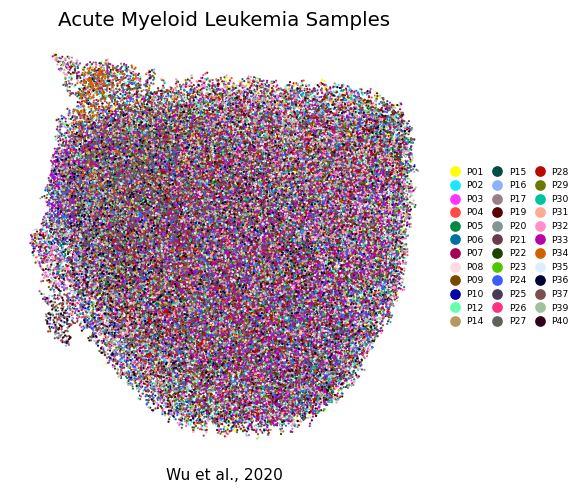

In [ ]:
# samples.pdf -- reference house style: single sample-coloured UMAP, external legend, citation
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='sample', size=8, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=3, frameon=False, loc='center left', bbox_to_anchor=(1.0, .5),
          columnspacing=.5, handletextpad=.25, fontsize=6)
ax.set_title('Acute Myeloid Leukemia Samples', size=13)
ax.text(.5, -.05, 'Wu et al., 2020', ha='center', transform=ax.transAxes)
plt.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('wrote samples.pdf')